# Indoor Location Prediction from Wi-Fi Signals: Phase 1 (Machine Learning)

**Task.** From one Wi-Fi scan (RSSI of up to 520 access points), predict the **building** (3 classes),
**floor** (up to 5) and **(x, y) coordinates** in metres.
**Data.** UJIIndoorLoc: 19,937 training scans and 1,111 validation scans (used as the held-out test set).

This notebook walks through the full Phase 1 pipeline. The reusable code is in `src/indoorloc/`; the
full experiment run (feature comparison, cross-validated tuning) is in `scripts/run_experiments.py`, and this
notebook reuses the settings it chose (`results/best_params.json`).

**Models:** Linear + Logistic Regression (baseline), k-NN (classic fingerprinting), Random Forest (main model).

In [1]:
import sys, json
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display

from indoorloc.data import load_raw, load_splits, split_xy, WAP_COLS, NOT_DETECTED
from indoorloc.features import FingerprintFeatures
from indoorloc.models import IndependentModel, HierarchicalModel, CentroidBaseline
from indoorloc.metrics import summarize, hierarchical_breakdown, per_group_error
pd.set_option("display.precision", 3)

## 1. Data and cleaning

In [2]:
raw = load_raw("train")
train, test, report = load_splits()
print(report)
print("train", train.shape, "| test", test.shape)
train.iloc[:3, list(range(5)) + list(range(520, 529))]

{'rows_in': 19937, 'duplicates_dropped': 637, 'empty_scans_dropped': 73, 'rows_out': 19227}
train (19227, 529) | test (1111, 529)


,WAP001,WAP002,WAP003,WAP004,WAP005,LONGITUDE,LATITUDE,FLOOR,BUILDINGID,SPACEID,RELATIVEPOSITION,USERID,PHONEID,TIMESTAMP
0,100,100,100,100,100,-7541.264,4.865e+06,2,1,106,2,2,23,1371713733
1,100,100,100,100,100,-7536.621,4.865e+06,2,1,106,2,2,23,1371713691
2,100,100,100,100,100,-7519.152,4.865e+06,2,1,103,2,2,23,1371714095


The value **+100 means "AP not detected"**. Real readings run from −104 to 0 dBm. About 96% of all
entries are +100. Used as a plain number, +100 would tell a model that undetected APs are the *strongest*.

In [3]:
W = train[WAP_COLS].to_numpy()
heard = W != NOT_DETECTED
print(f"missing fraction: {1 - heard.mean():.3f}")
print(f"APs heard per scan: mean {heard.sum(1).mean():.1f}, median {np.median(heard.sum(1)):.0f}")
print(f"APs never heard in training: {(~heard.any(0)).sum()}")

missing fraction: 0.965
APs heard per scan: mean 17.9, median 17
APs never heard in training: 55


## 2. Exploratory data analysis
Figures are produced by `scripts/run_eda.py`.

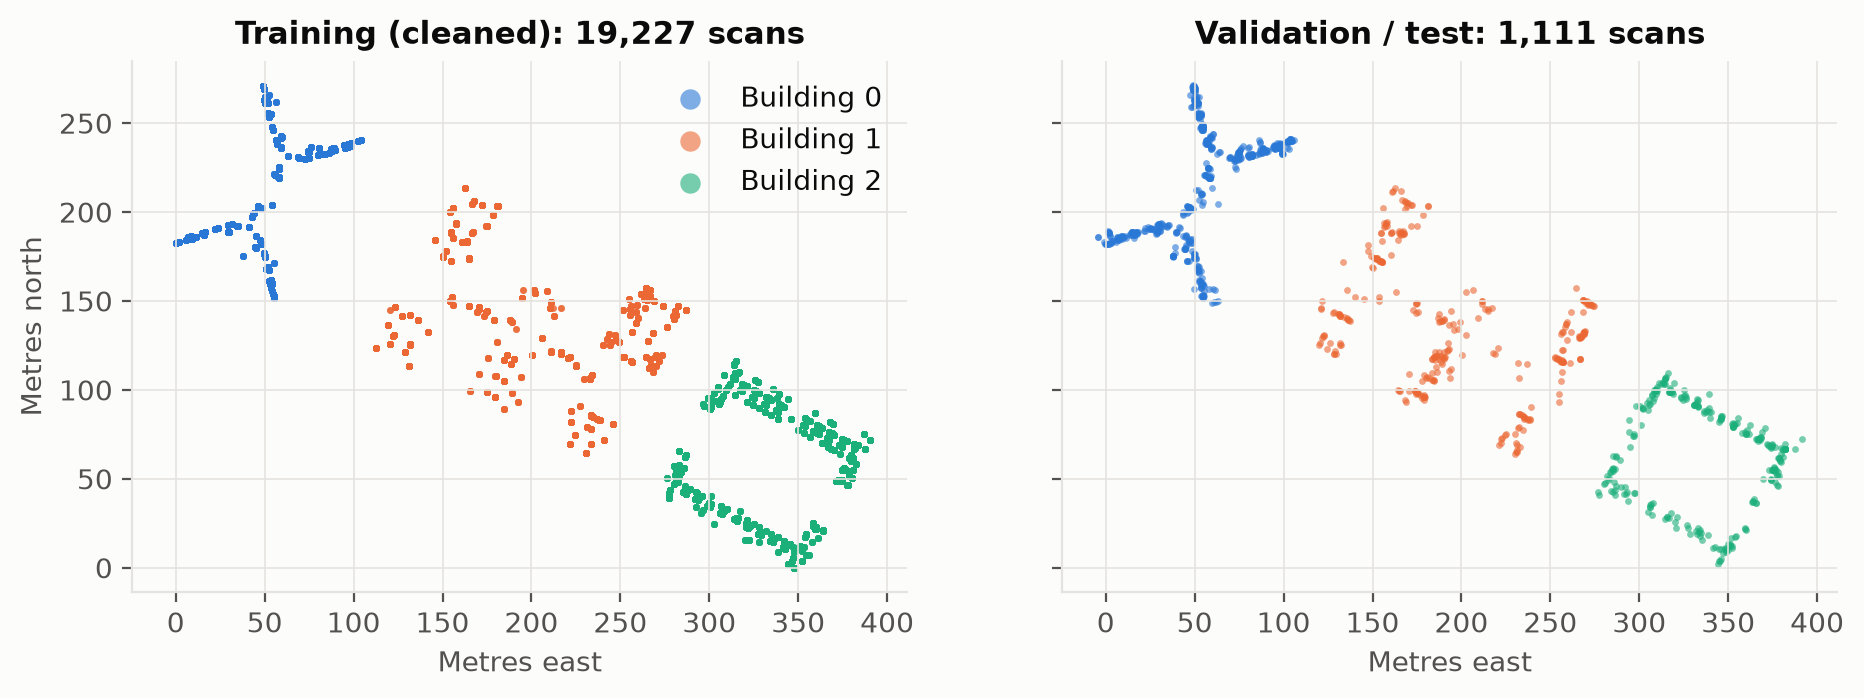

In [4]:
display(Image("../results/figures/eda_campus_map.png"))

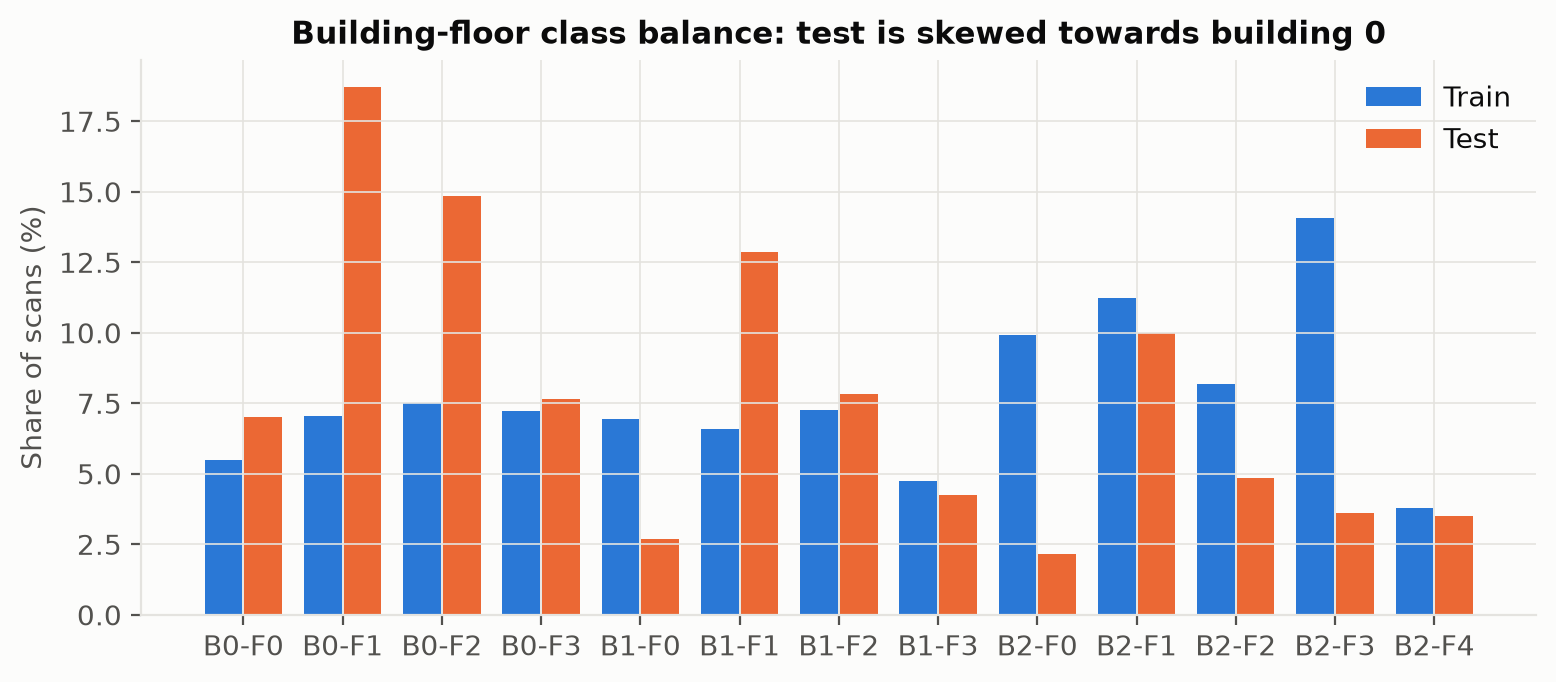

In [5]:
display(Image("../results/figures/eda_class_balance.png"))

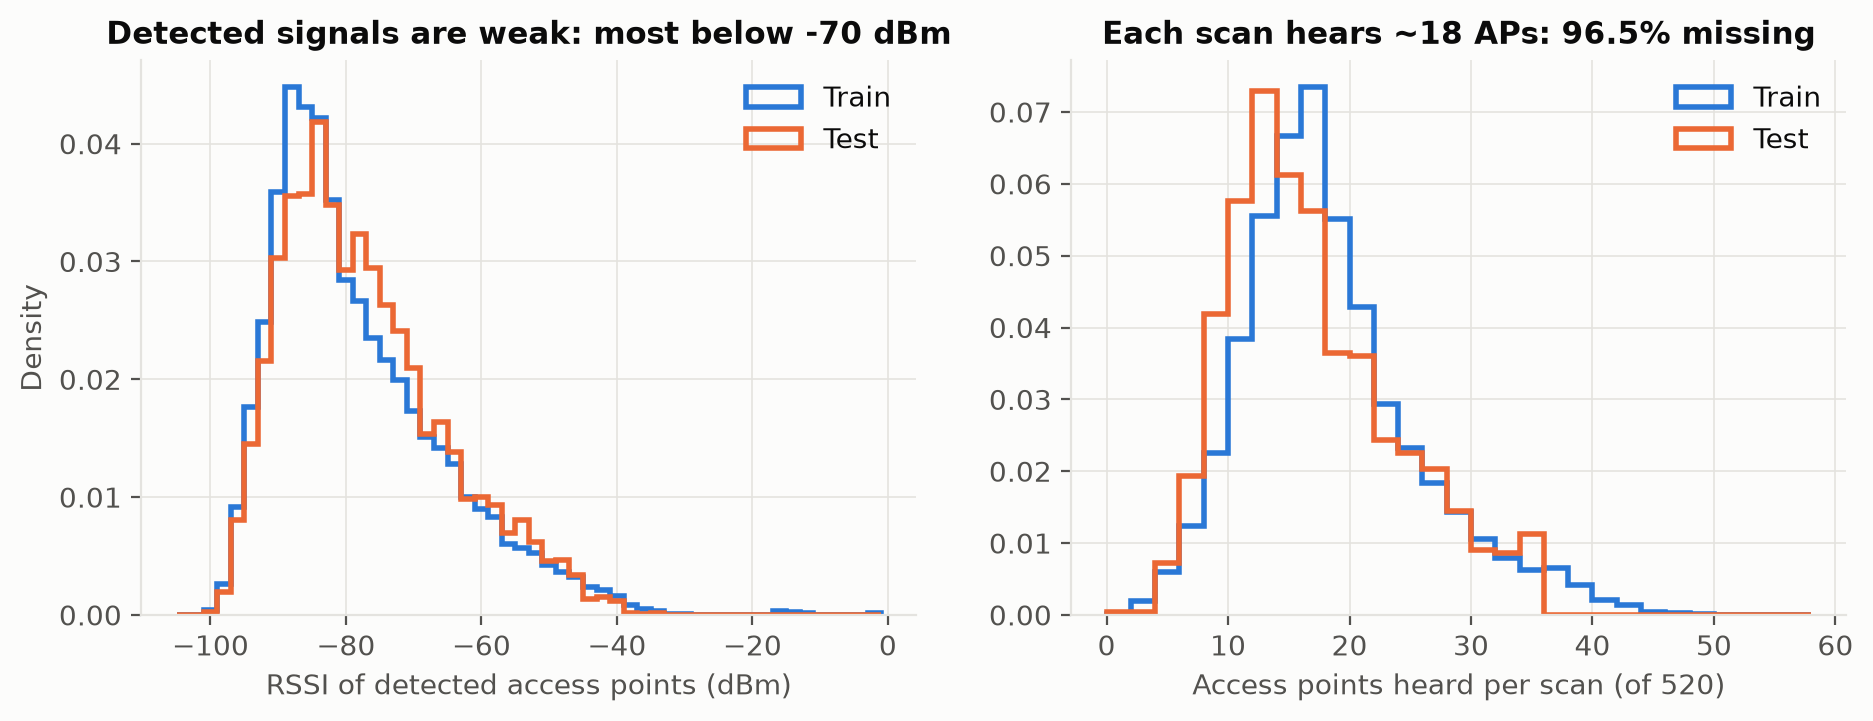

In [6]:
display(Image("../results/figures/eda_rssi_distribution.png"))

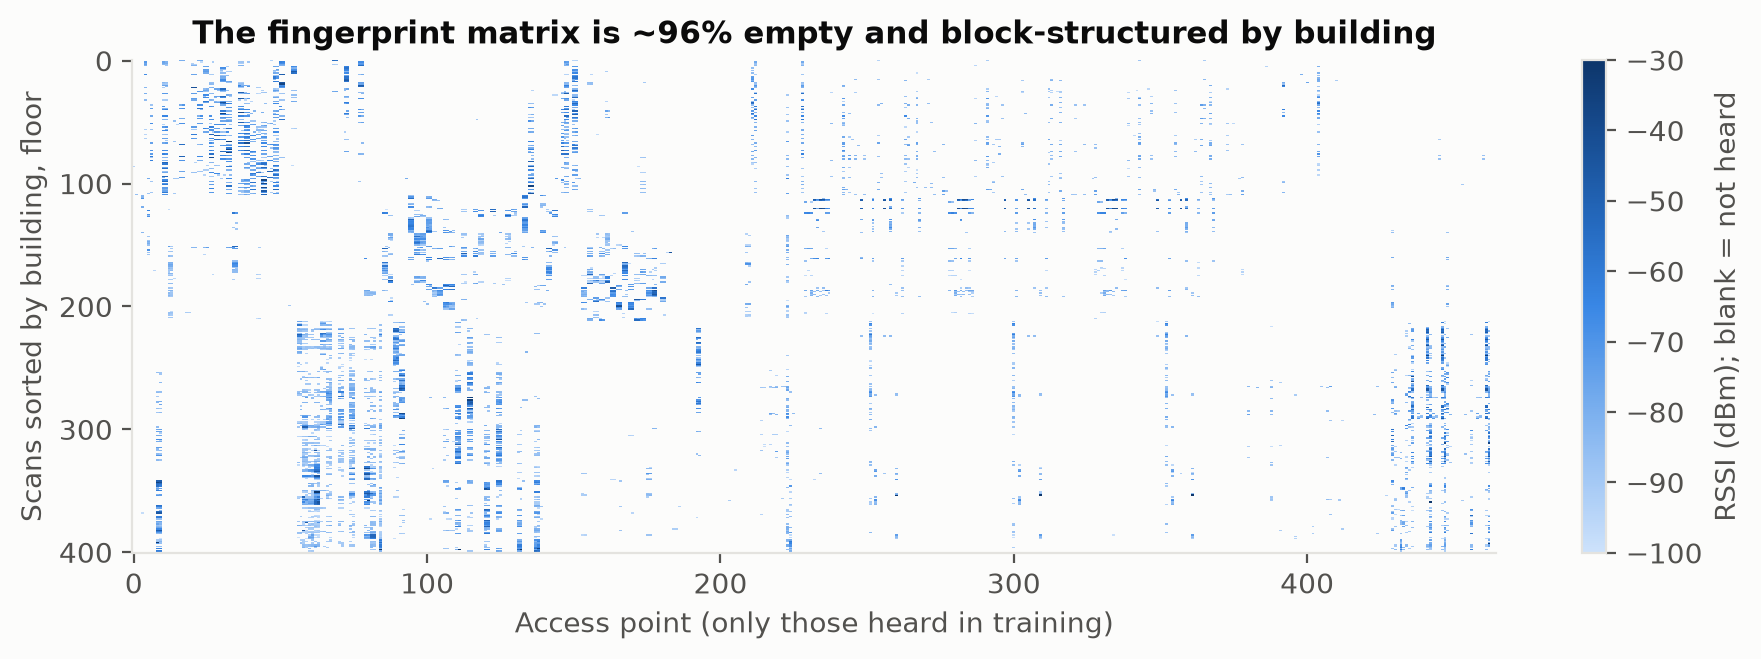

In [7]:
display(Image("../results/figures/eda_sparsity_heatmap.png"))

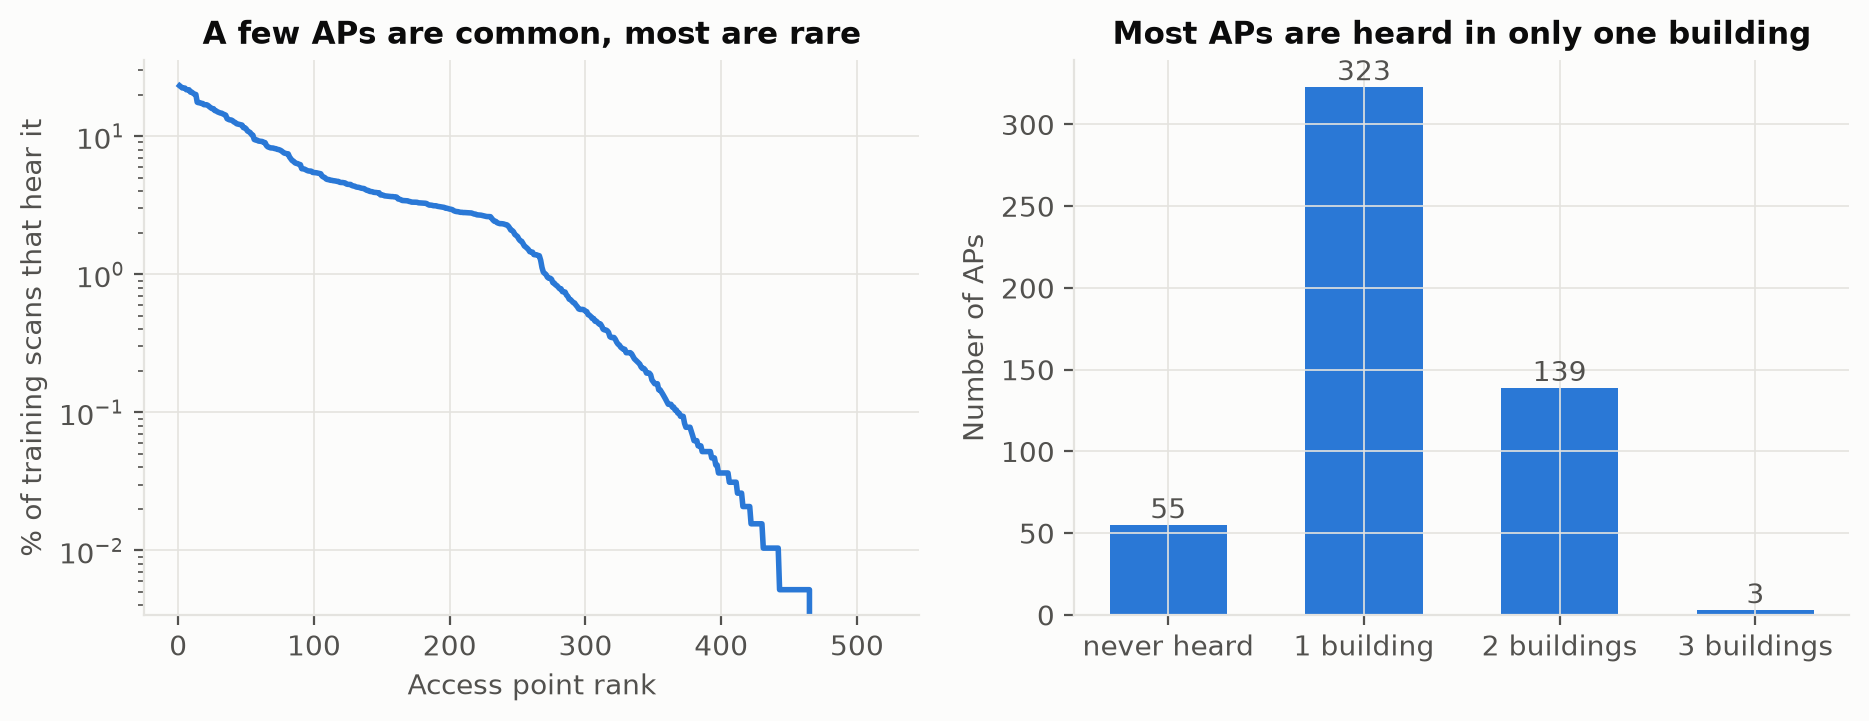

In [8]:
display(Image("../results/figures/eda_ap_locality.png"))

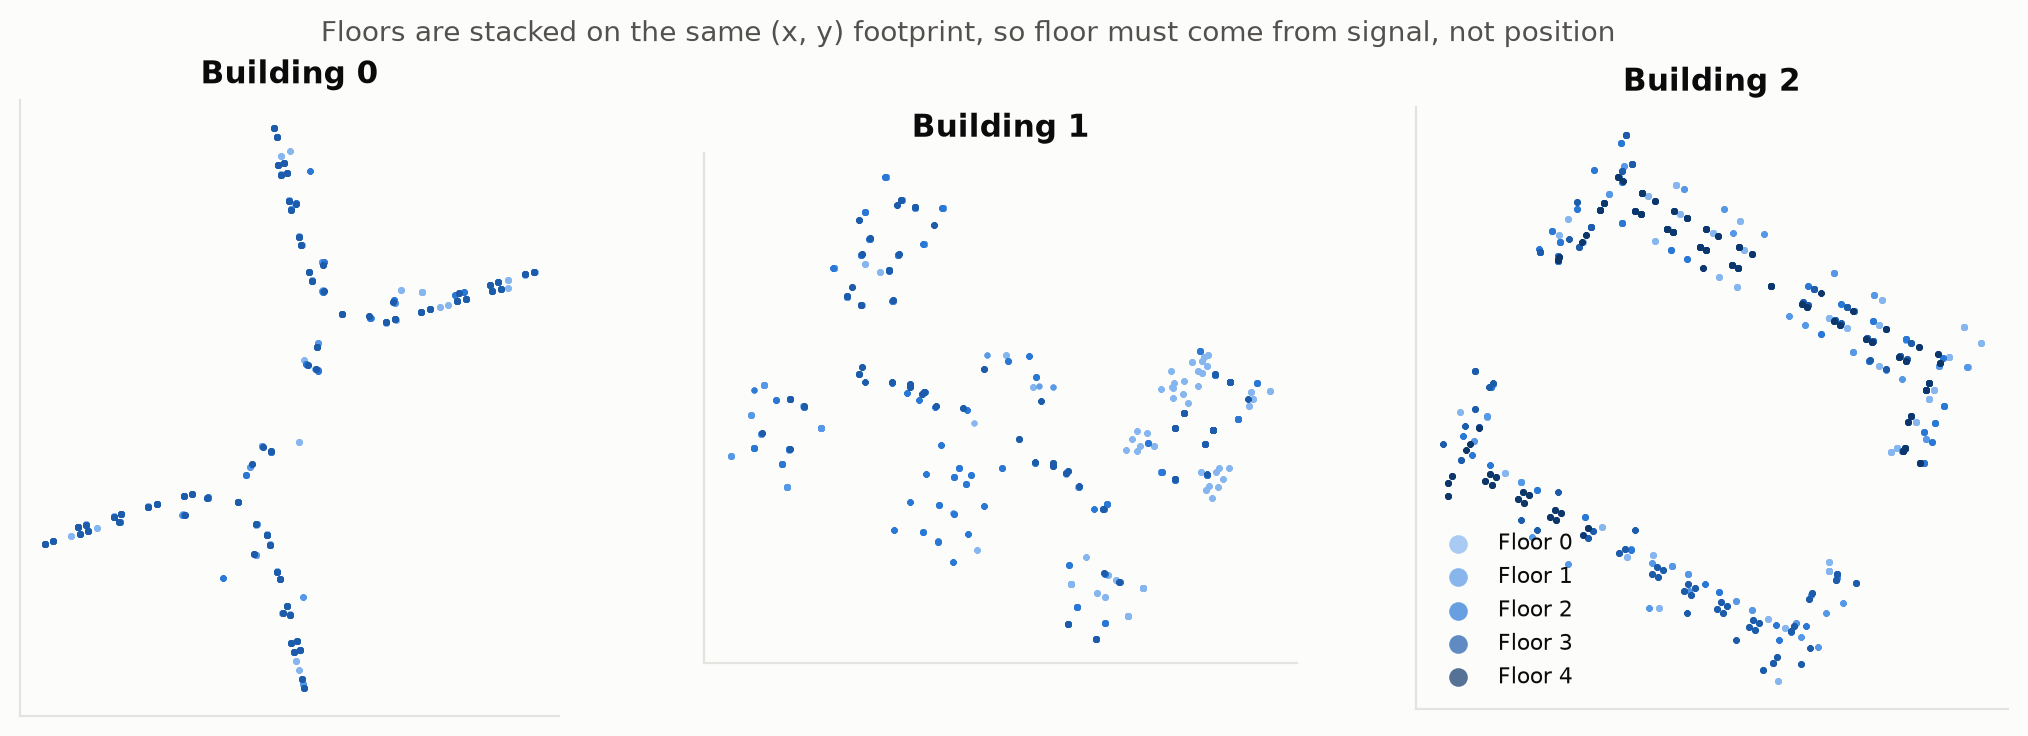

In [9]:
display(Image("../results/figures/eda_floors_per_building.png"))

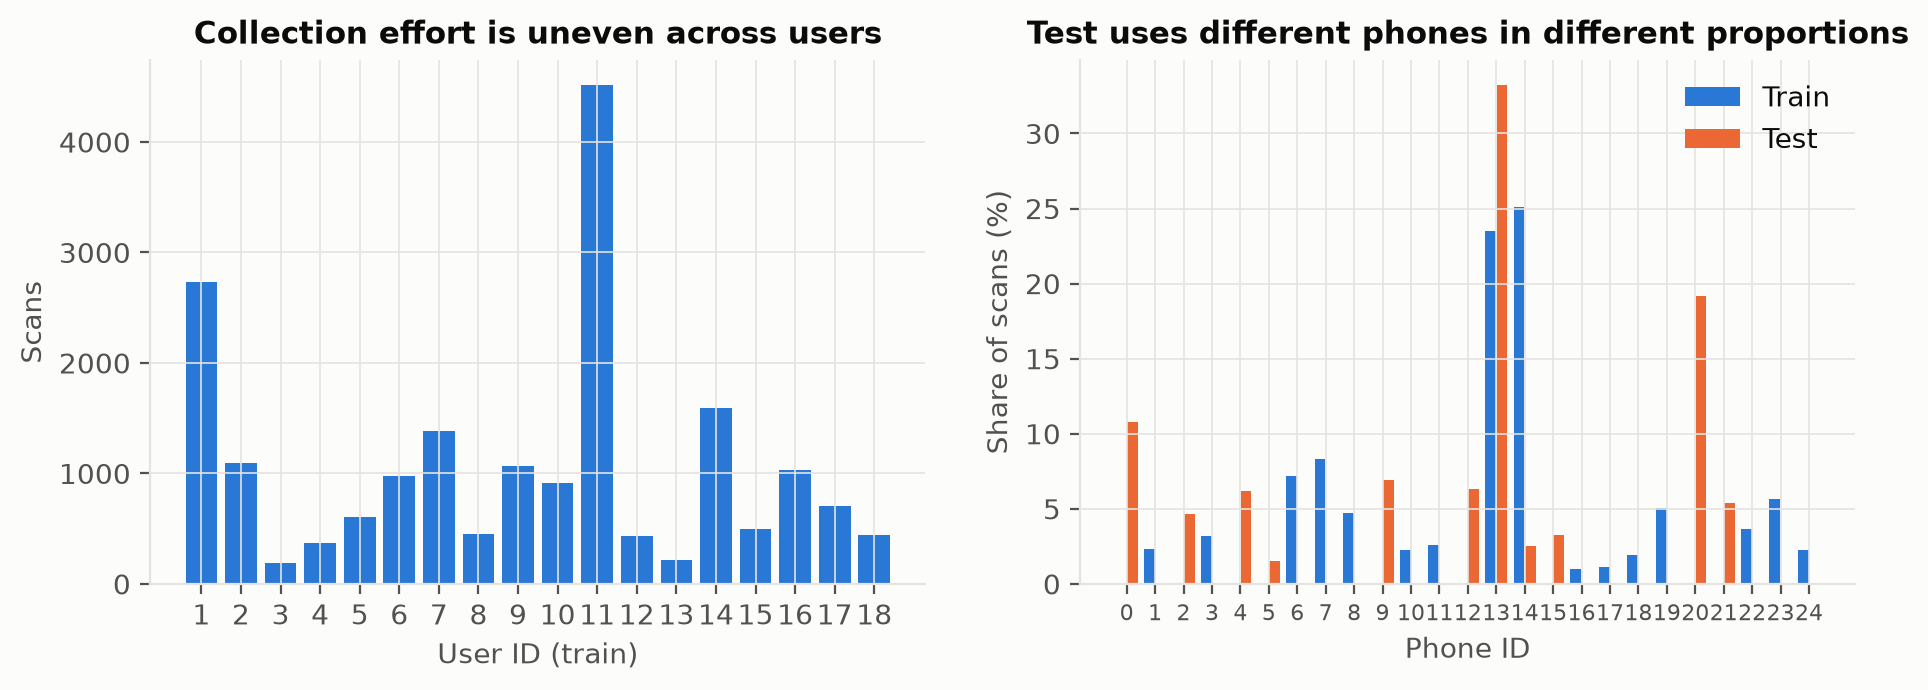

In [10]:
display(Image("../results/figures/eda_users_phones.png"))

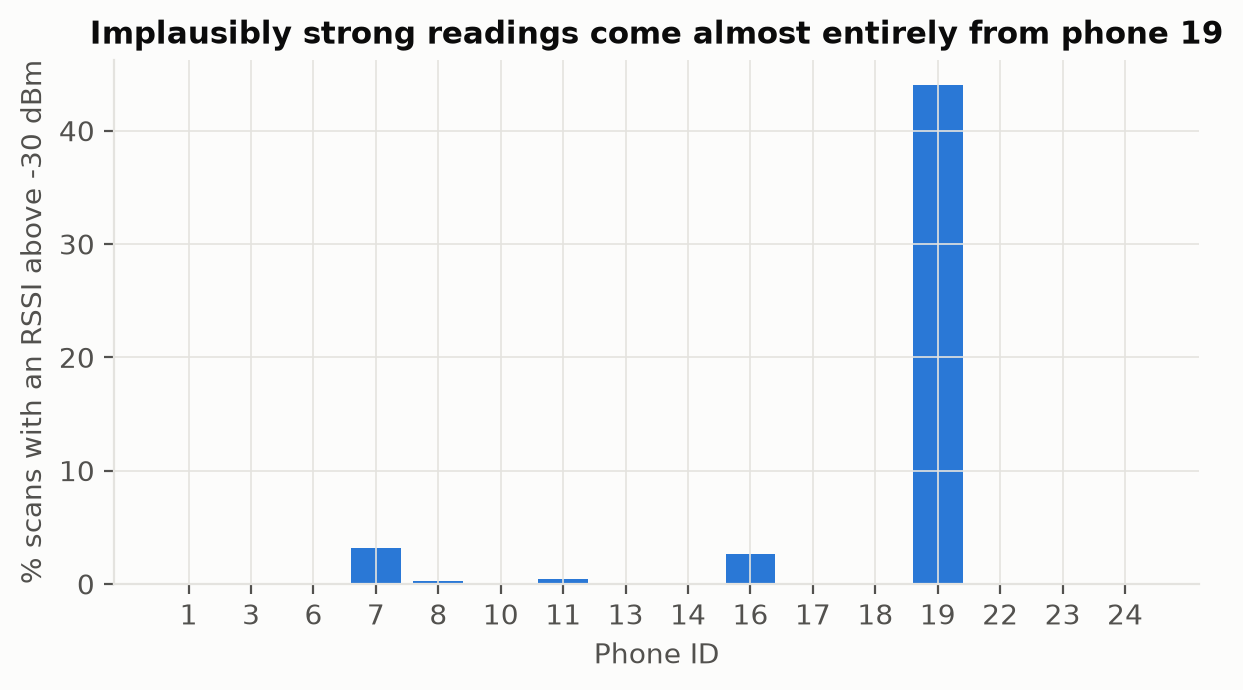

In [11]:
display(Image("../results/figures/eda_suspicious_readings.png"))

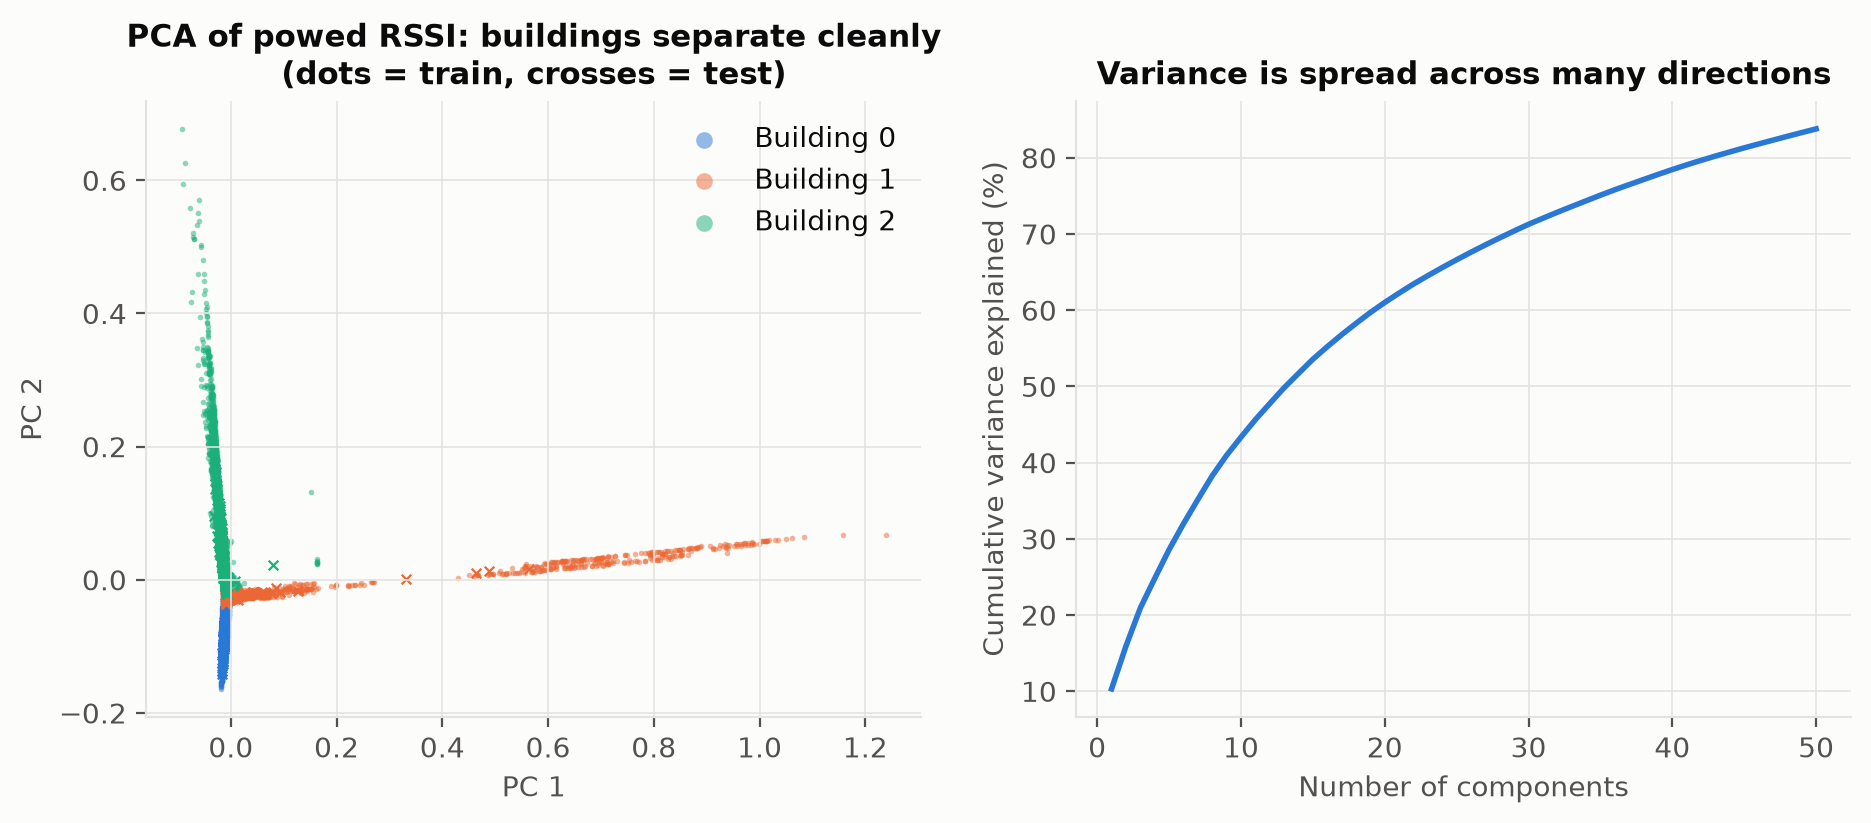

In [12]:
display(Image("../results/figures/eda_pca.png"))

**Takeaways.** (1) Buildings are physically and radio-separated: most APs are heard in one building only,
so building classification is easy. (2) Floors share the same footprint, so floor must come from the signal.
(3) The test set is skewed to building 0, was collected 4 months later, and 64% of its scans come from phones
not present in training. (4) Phone 19 produces implausibly strong readings (> −30 dBm).

## 3. Feature engineering
The main step is replacing **+100 ("not heard") with −105 dBm**, just below the weakest real reading. We also tried
other versions (shifted, compressed, heard/not-heard flags, per-scan summary). Cross-validation on unseen users chose
between them.

In [13]:
Xtr, ytr, mtr = split_xy(train)
Xte, yte, mte = split_xy(test)
fe = FingerprintFeatures(representation="raw", add_indicators=False, add_summary=False).fit(Xtr)
Z = fe.transform(Xtr)
print("APs kept (heard at least once in training):", len(fe.keep_))
print("value used for 'not heard':", fe.floor_)
print("example scan, first 8 APs:", Z[0, :8])

APs kept (heard at least once in training): 465
value used for 'not heard': -105.0
example scan, first 8 APs: [-105. -105. -105. -105. -105. -105. -105. -105.]


In [14]:
abl = pd.read_csv("../results/ablation_features.csv")
abl[["model", "features", "cv_ipin_score_m", "test_ipin_score_m", "test_building_floor_acc", "test_mean_error_m"]]

,model,features,cv_ipin_score_m,test_ipin_score_m,test_building_floor_acc,test_mean_error_m
0,Random Forest (per-building),"raw dBm, not-heard = -105",15.229,9.703,0.912,9.309
1,Random Forest (per-building),positive (shifted so not-heard = 0),15.229,9.703,0.912,9.309
2,Random Forest (per-building),powed (compress weak signals),15.705,9.883,0.911,9.440
3,Random Forest (per-building),raw + heard/not-heard flags,15.553,10.276,0.903,9.797
4,Random Forest (per-building),raw + flags + scan summary,15.819,9.865,0.910,9.505
5,k-NN (k=5),"raw dBm, not-heard = -105",14.456,9.222,0.901,8.691
6,k-NN (k=5),positive (shifted so not-heard = 0),14.456,9.222,0.901,8.691
7,k-NN (k=5),powed (compress weak signals),17.601,8.581,0.934,8.187
8,k-NN (k=5),raw + heard/not-heard flags,14.535,9.196,0.900,8.662


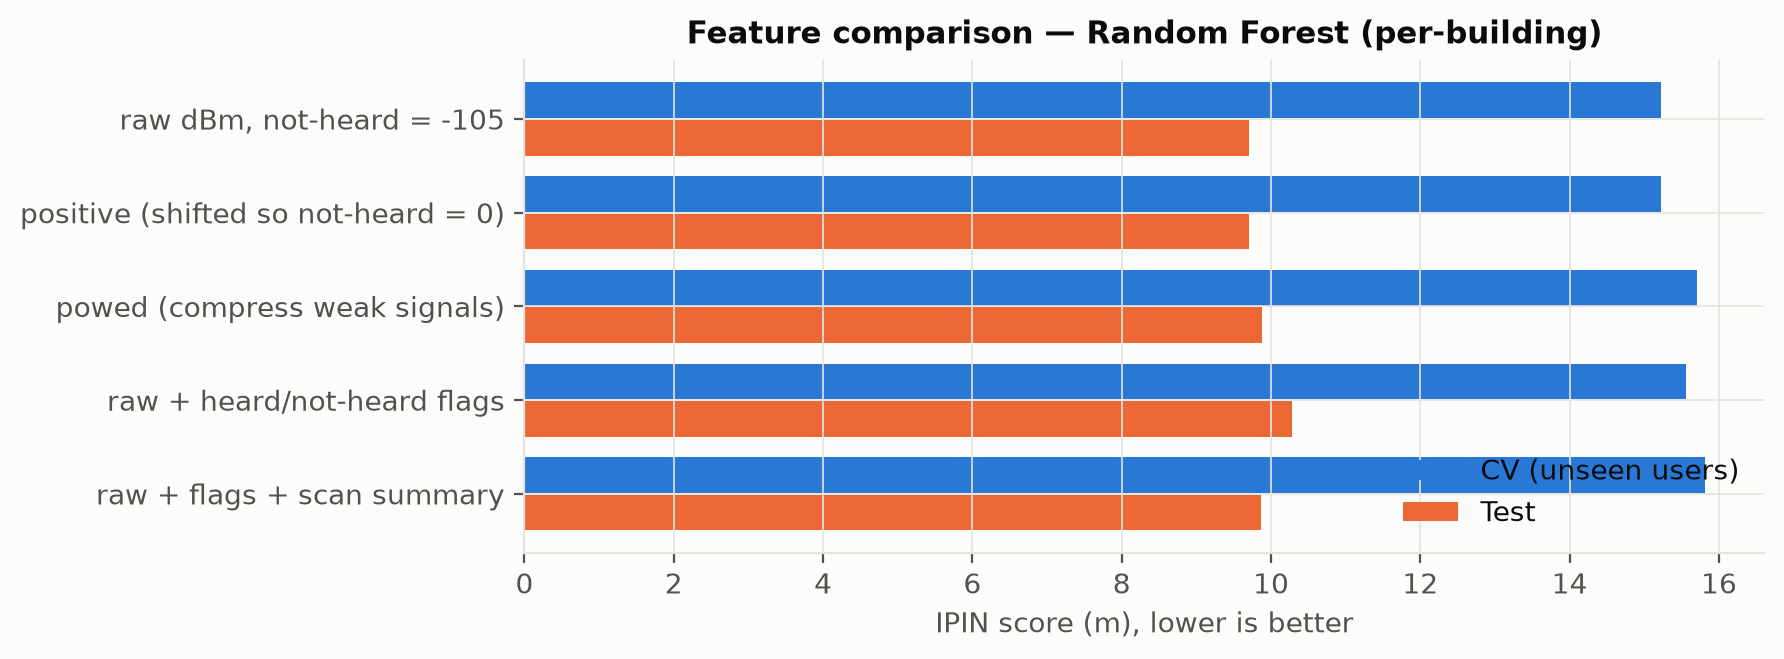

In [15]:
display(Image("../results/figures/ablation_features.png"))

**Raw and shifted give exactly the same result.** A tree only asks "is this AP above a threshold?", and shifting
every value by the same amount keeps their order. k-NN uses distances, and shifting both scans by the same amount
does not change the distance between them. The extra features did not help, so we keep the simple version.

## 4. Choosing hyper-parameters with cross-validation (5 folds, each holding out whole users)

In [16]:
tuning = pd.read_csv("../results/tuning_cv.csv")
best = json.load(open("../results/best_params.json"))
summary = json.load(open("../results/summary.json"))
print("chosen:", best)
tuning[["model", "params", "building_floor_acc", "mean_error_m", "ipin_score_m"]]

chosen: {'k-NN': {'k': 5}, 'Random Forest': {'max_features': 'sqrt', 'n_estimators': 300}}


,model,params,building_floor_acc,mean_error_m,ipin_score_m
0,k-NN,"{""k"": 1}",0.724,12.921,15.551
1,k-NN,"{""k"": 3}",0.723,12.101,14.705
2,k-NN,"{""k"": 5}",0.723,11.778,14.456
3,k-NN,"{""k"": 7}",0.723,11.805,14.734
4,k-NN,"{""k"": 11}",0.721,11.928,15.052
5,Random Forest,"{""max_features"": ""sqrt"", ""n_estimators"": 300}",0.709,13.552,15.213
6,Random Forest,"{""max_features"": 0.1, ""n_estimators"": 300}",0.716,14.380,16.080
7,Random Forest,"{""max_features"": 0.3, ""n_estimators"": 300}",0.709,15.575,17.446


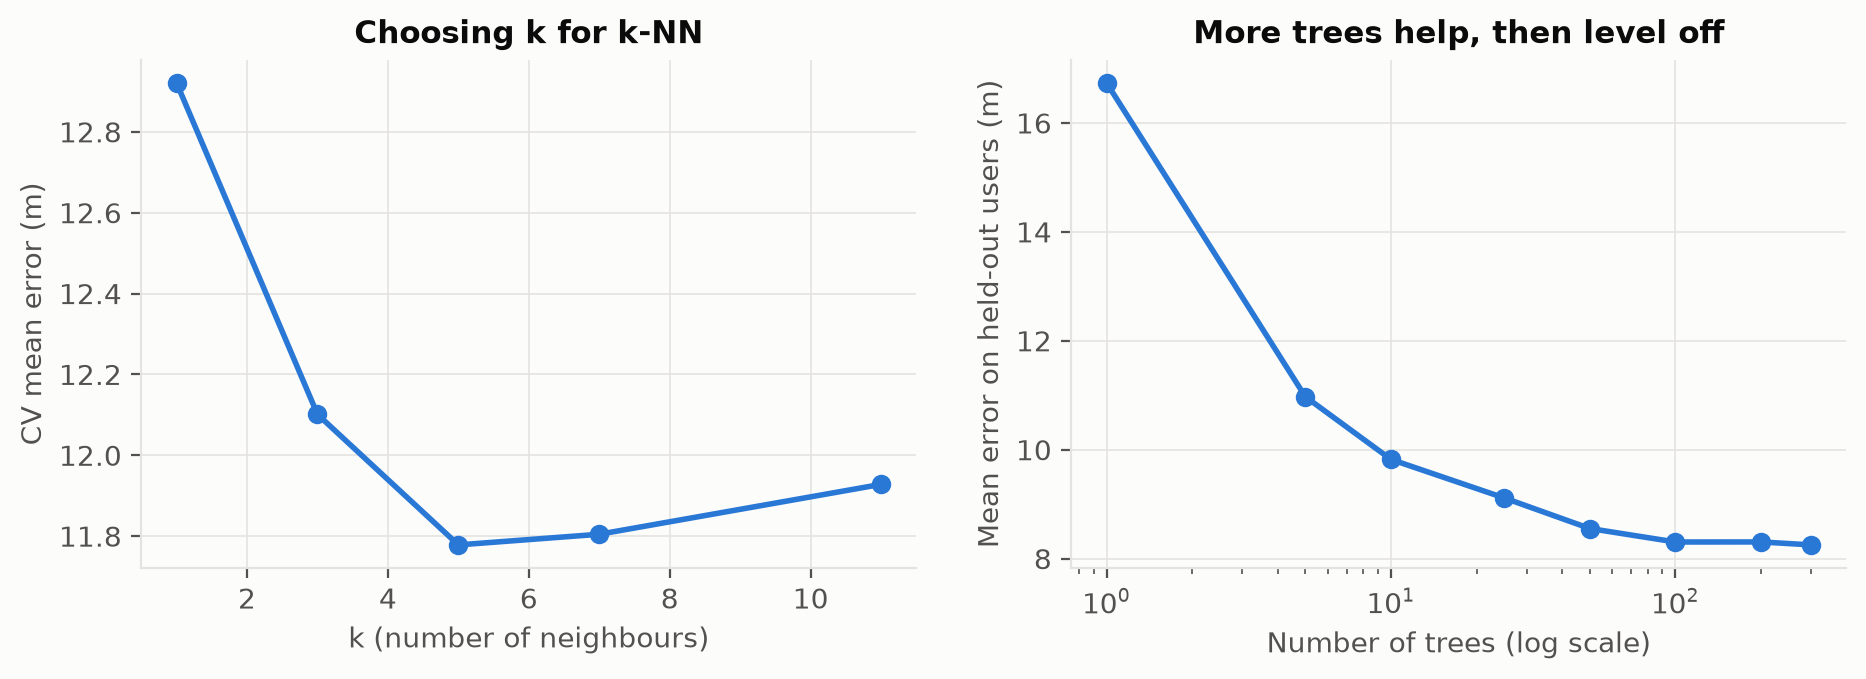

In [17]:
display(Image("../results/figures/tuning_curves.png"))

## 5. Train the final models on all training data and test on the validation file

In [18]:
F = FingerprintFeatures
rf_f, knn_f = summary["rf_features"], summary["knn_features"]
raw = dict(representation="raw", add_indicators=False, add_summary=False)
models = {
    "Centroid": CentroidBaseline(),
    "Linear + Logistic Regression": IndependentModel("linear", features=F(**raw)),
    "k-NN": IndependentModel("knn", features=F(**knn_f), **best["k-NN"]),
    "Random Forest": IndependentModel("rf", features=F(**rf_f), **best["Random Forest"]),
    "Random Forest (per-building)": HierarchicalModel("rf", features=F(**rf_f), **best["Random Forest"]),
}
preds, rows = {}, []
for name, m in models.items():
    m.fit(Xtr, ytr)
    preds[name] = m.predict(Xte)
    rows.append({"model": name, **summarize(yte, preds[name])})
results = pd.DataFrame(rows).set_index("model")
results[["building_acc", "floor_acc", "building_floor_acc", "mean_error_m", "median_error_m", "ipin_score_m"]]

,building_acc,floor_acc,building_floor_acc,mean_error_m,median_error_m,ipin_score_m
model,,,,,,
Centroid,0.241,0.155,0.036,142.754,167.374,184.074
Linear + Logistic Regression,1.000,0.887,0.887,51.995,37.528,52.449
k-NN,0.997,0.901,0.901,8.691,5.355,9.222
Random Forest,0.998,0.909,0.908,10.222,7.629,10.676
Random Forest (per-building),0.998,0.913,0.912,9.366,7.073,9.805


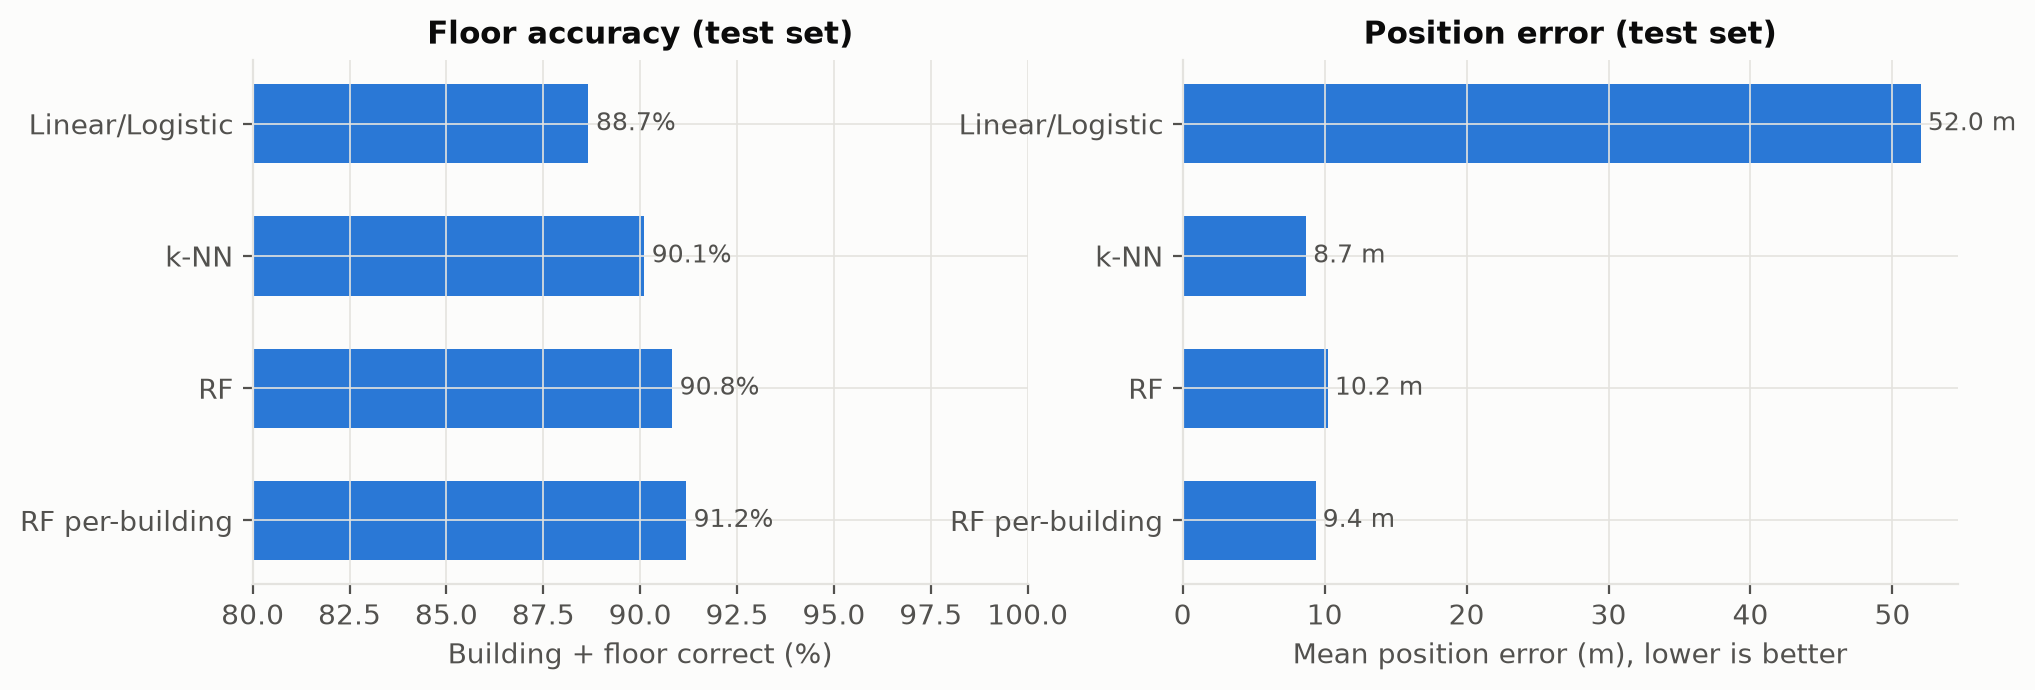

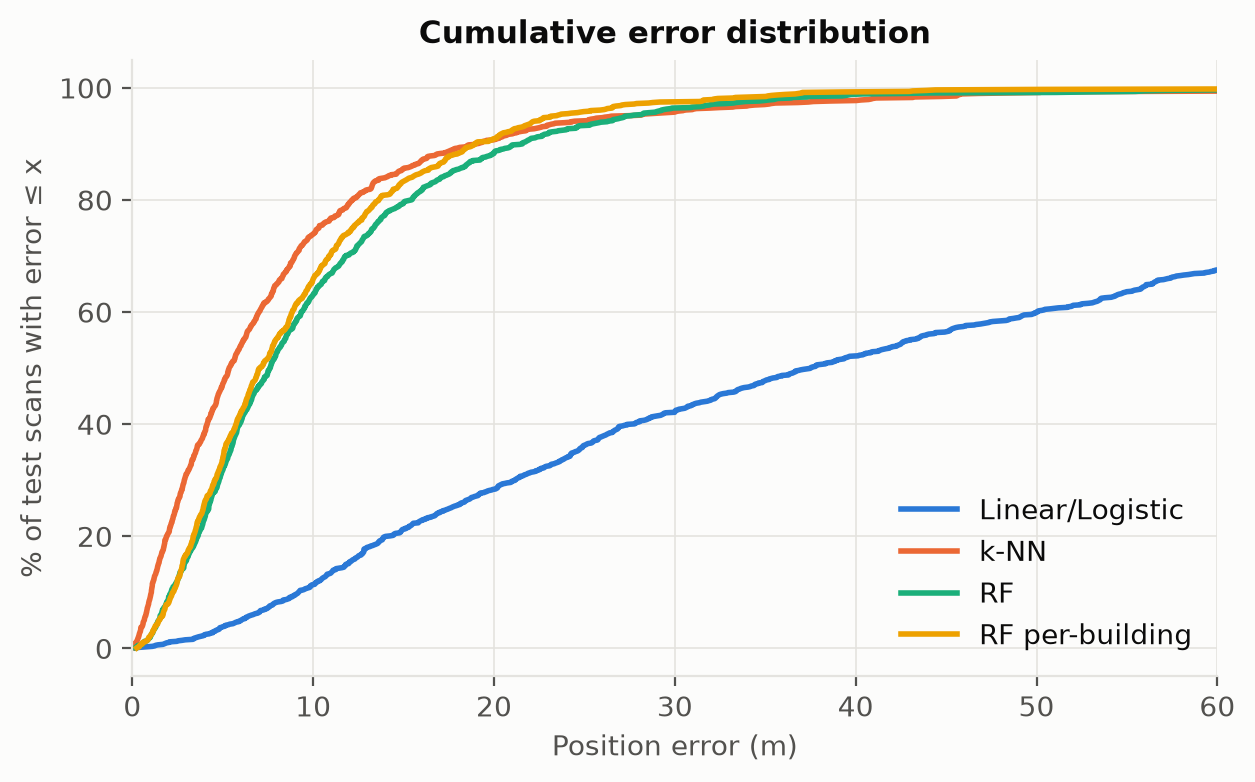

In [19]:
display(Image("../results/figures/model_comparison.png"))
display(Image("../results/figures/error_cdf.png"))

## 6. Error analysis of the main model (Random Forest, per-building)

In [20]:
p = preds["Random Forest (per-building)"]
hierarchical_breakdown(yte, p)

,case,count,mean,median,share_of_total_error
0,"building ok, floor ok",1013,8.570,6.648,0.834
1,"building ok, floor wrong",96,15.728,12.553,0.145
2,building wrong,2,107.255,107.255,0.021


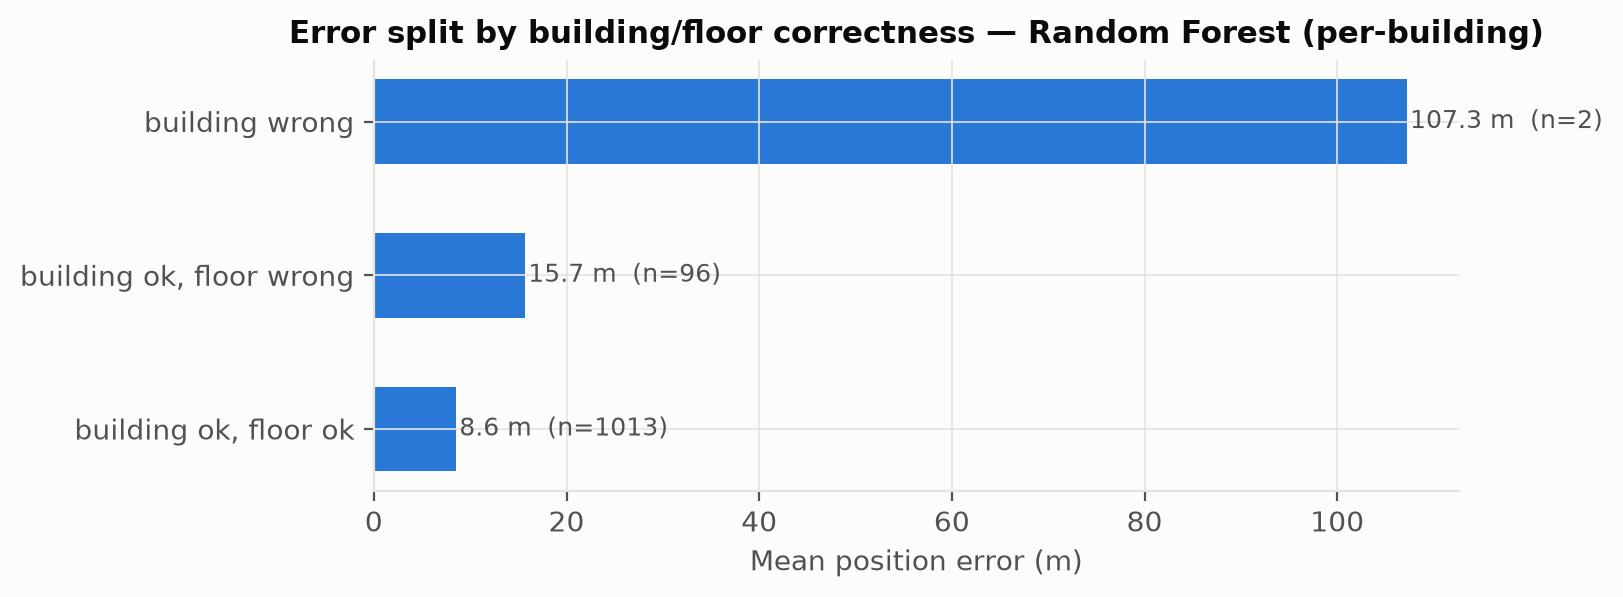

In [21]:
display(Image("../results/figures/hierarchical_breakdown.png"))

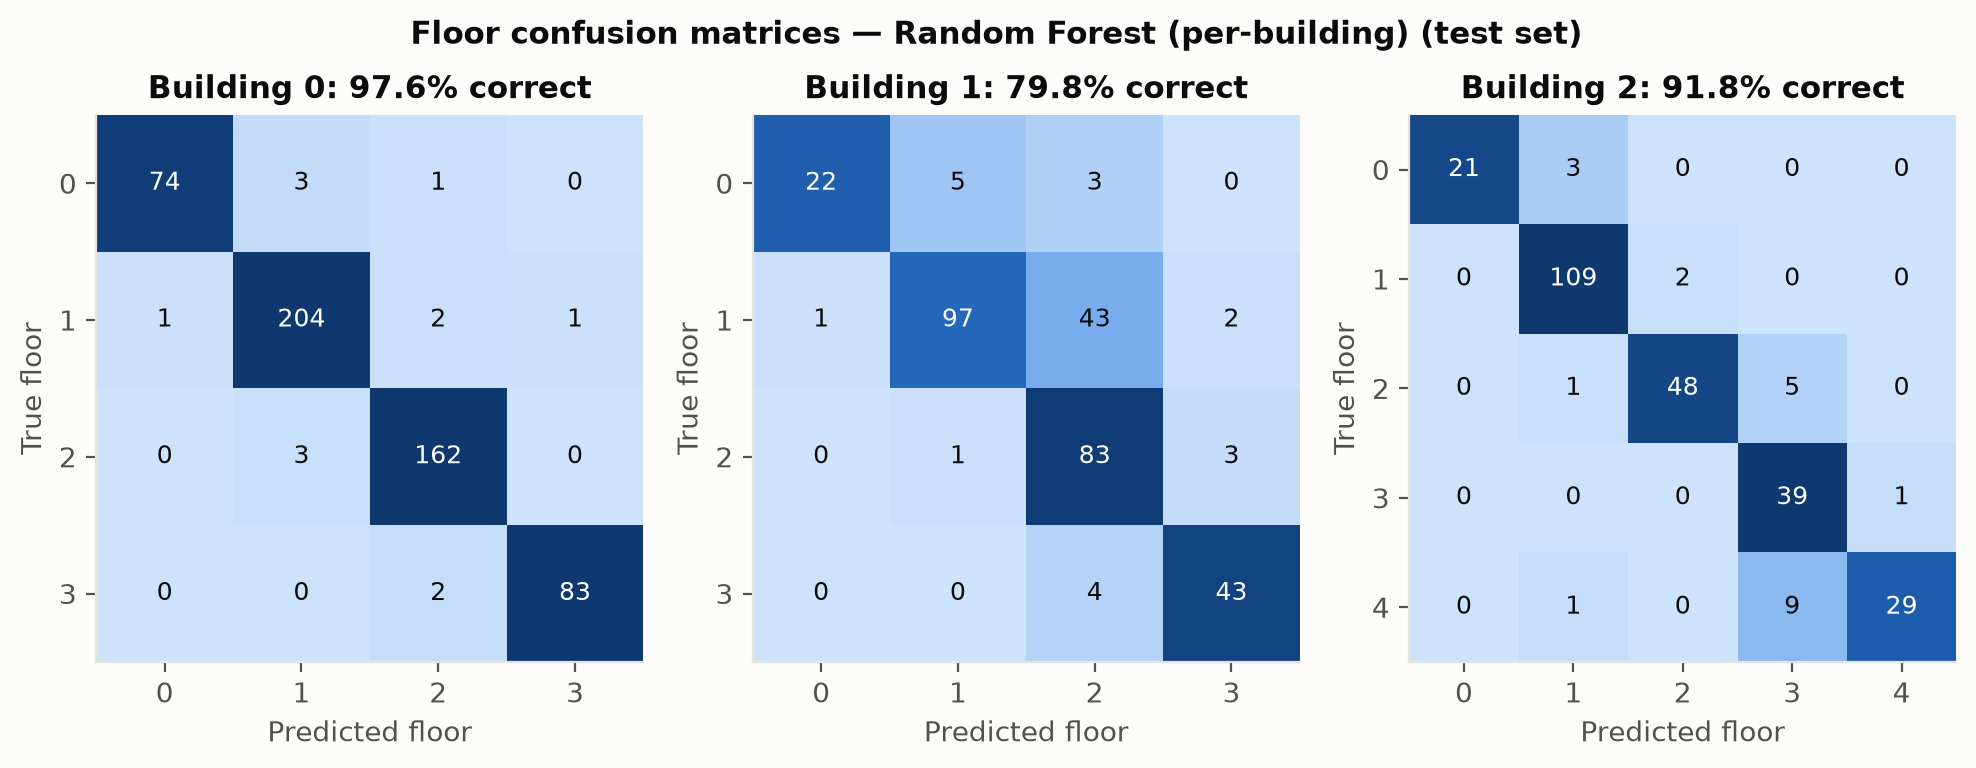

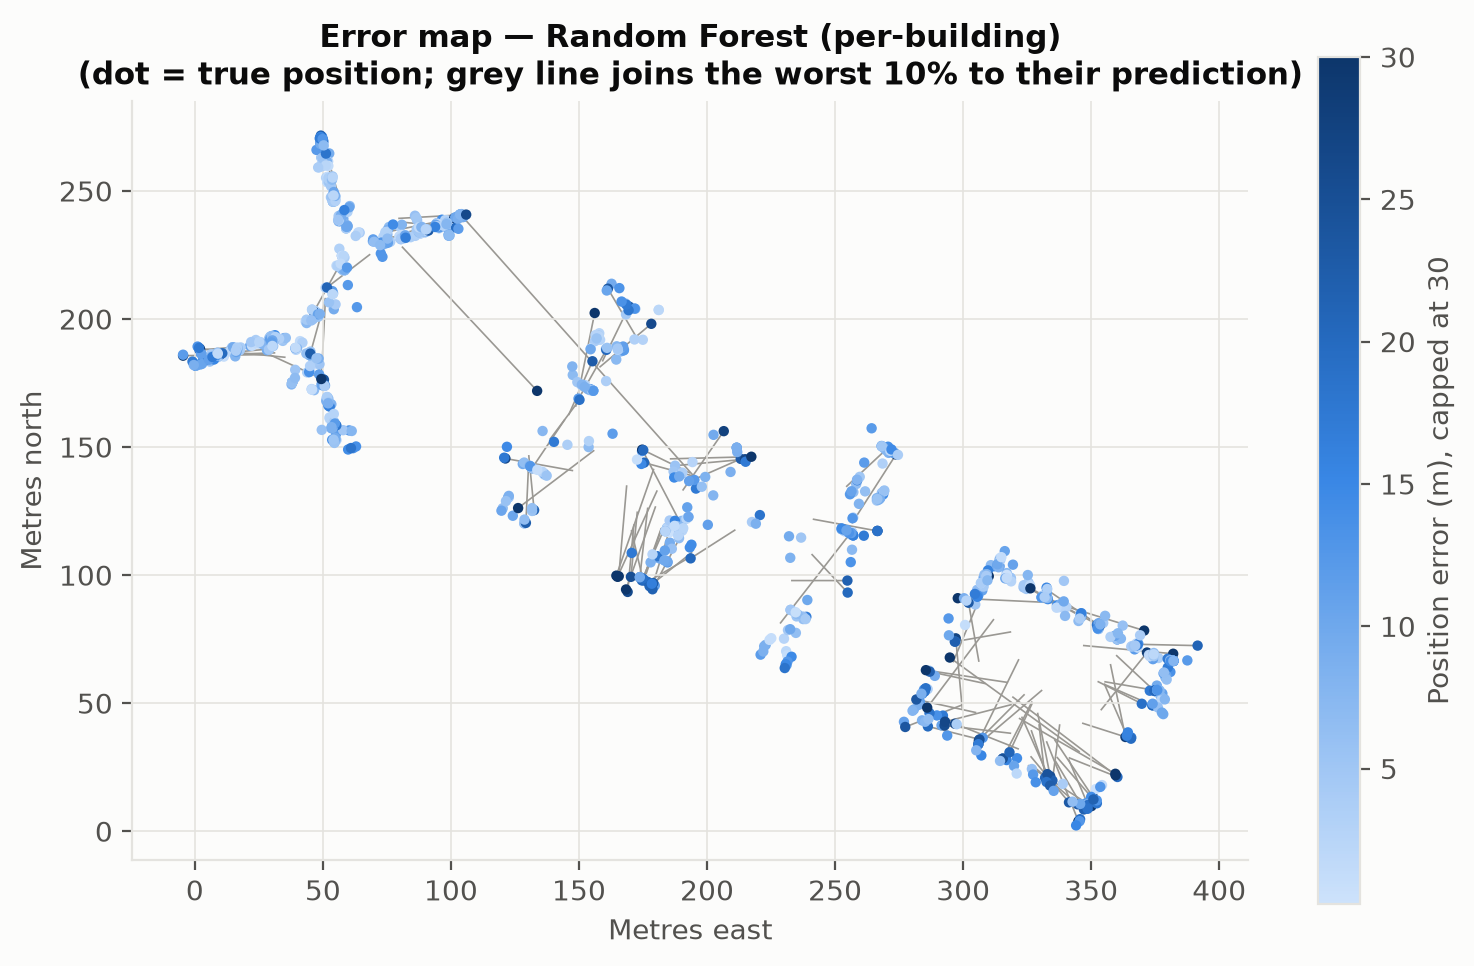

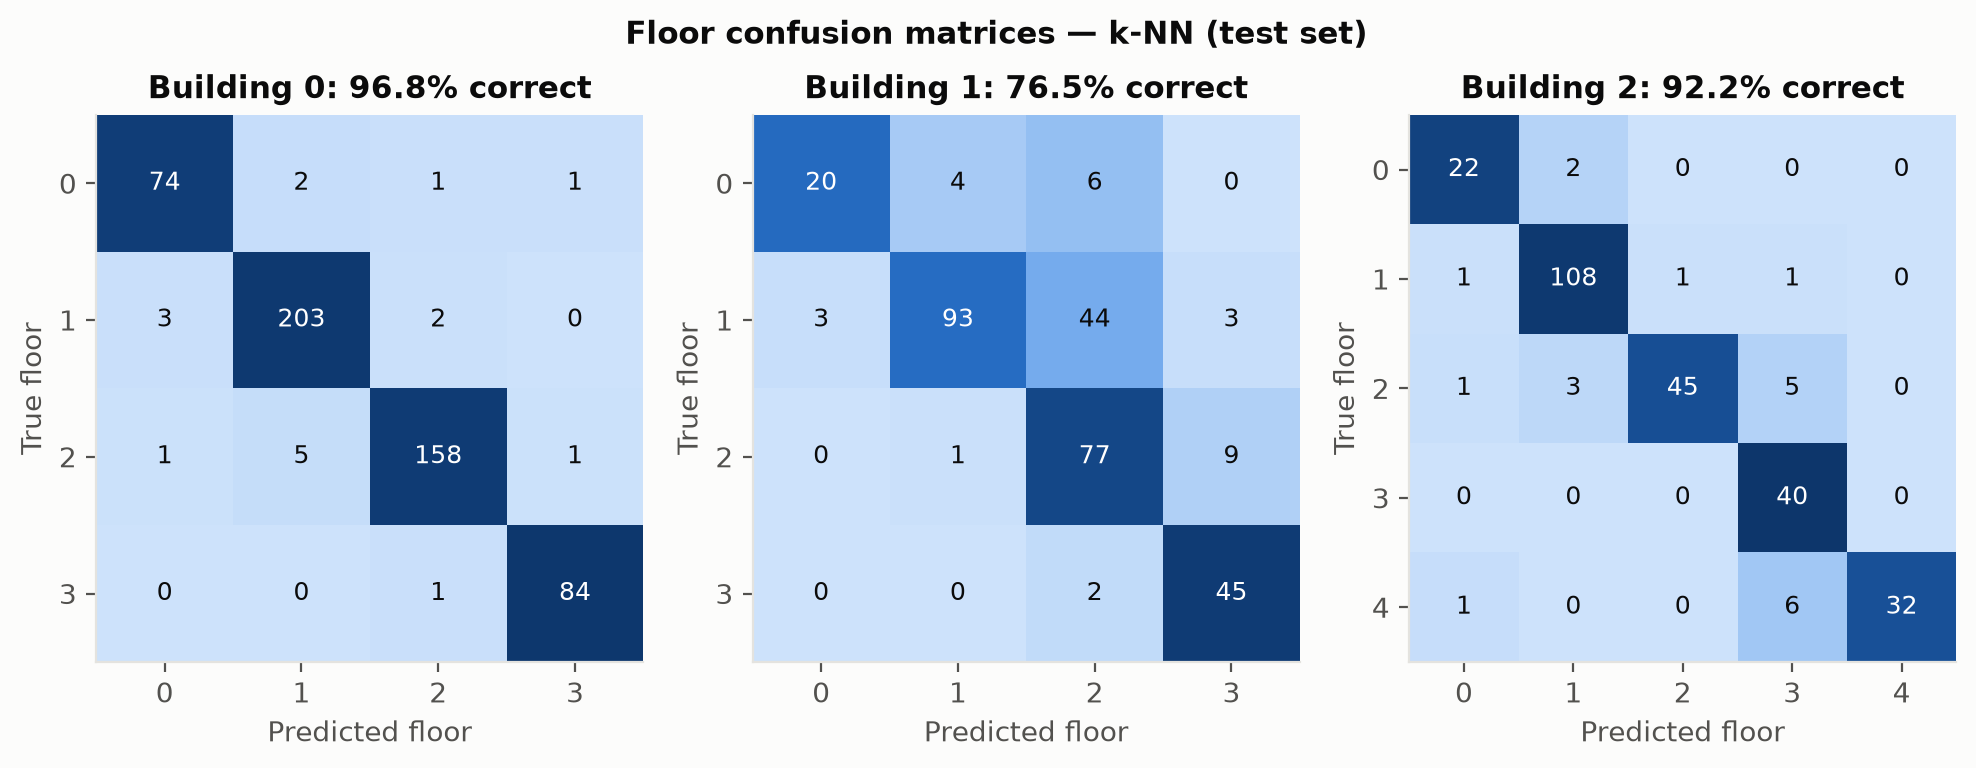

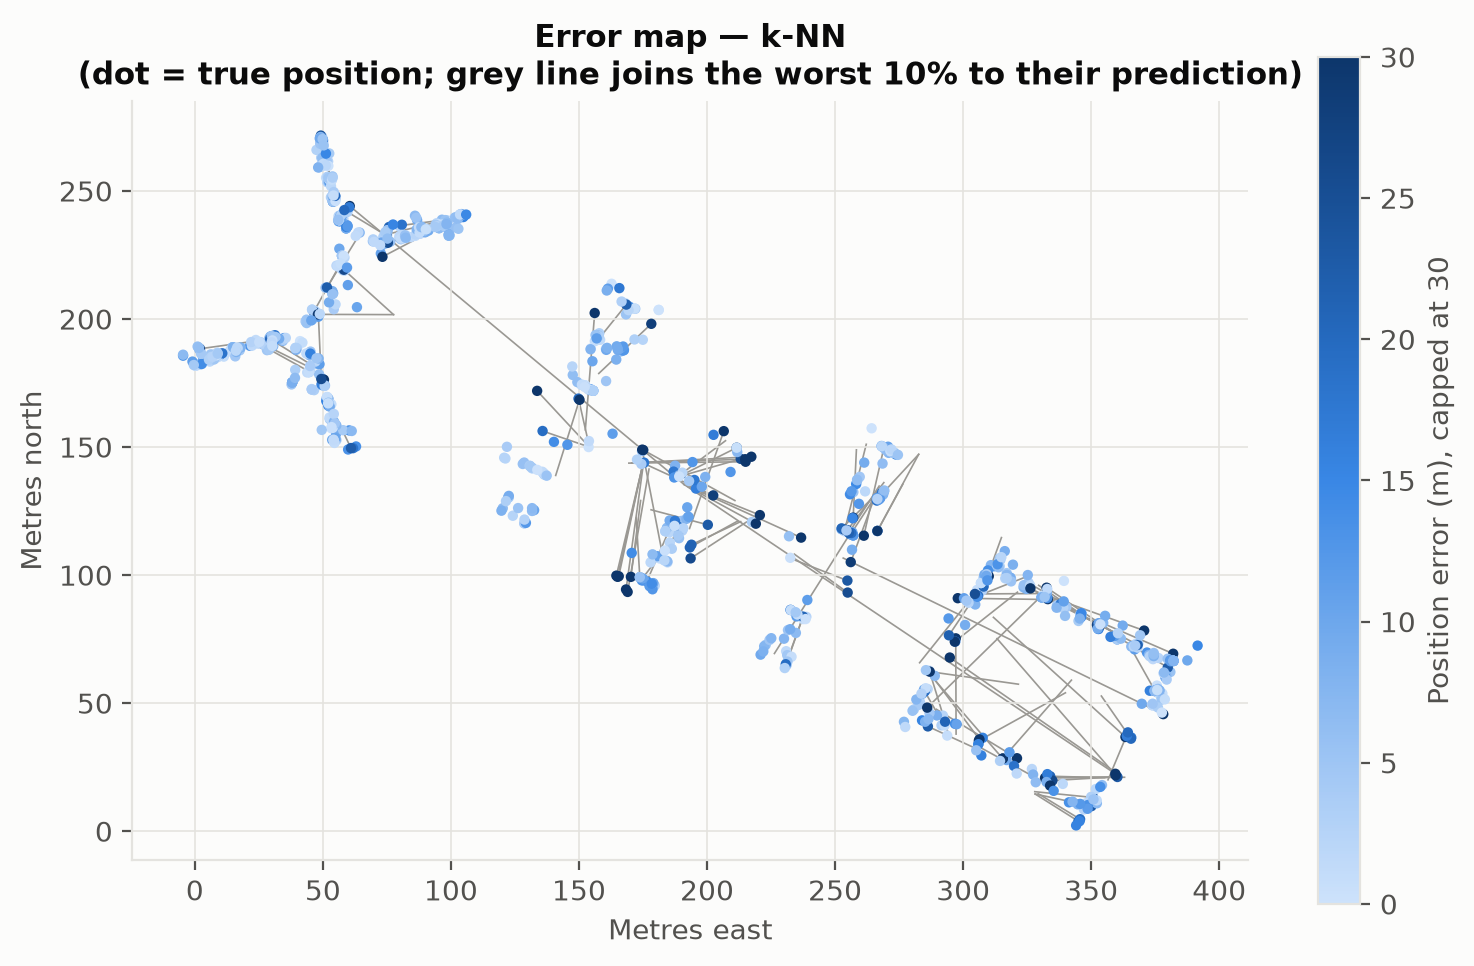

In [22]:
for f in ["confusion_floor_rf", "error_map_rf", "confusion_floor_knn", "error_map_knn"]:
    display(Image(f"../results/figures/{f}.png"))

In [23]:
per_group_error(yte, p, mte["PHONEID"])

,PHONEID,n,mean_error_m,median_error_m,building_floor_acc
0,0,120,8.224,5.856,0.908
1,2,52,9.769,6.562,0.846
2,4,69,7.178,5.530,0.913
3,5,17,8.939,6.281,0.706
4,9,77,6.234,5.701,0.922
5,12,70,10.666,9.729,0.914
6,13,369,7.440,5.251,0.940
7,14,28,16.318,14.479,0.786
8,15,36,7.722,7.482,0.917
9,20,213,13.237,11.641,0.892


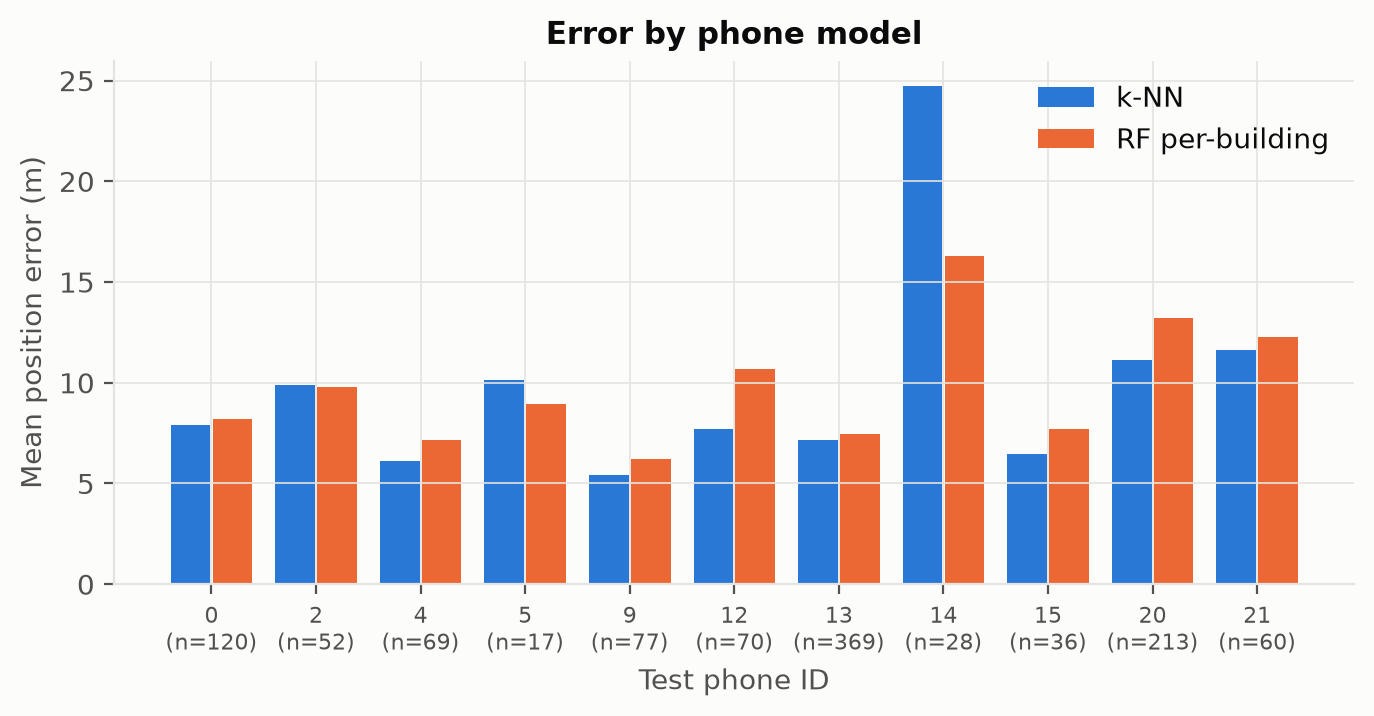

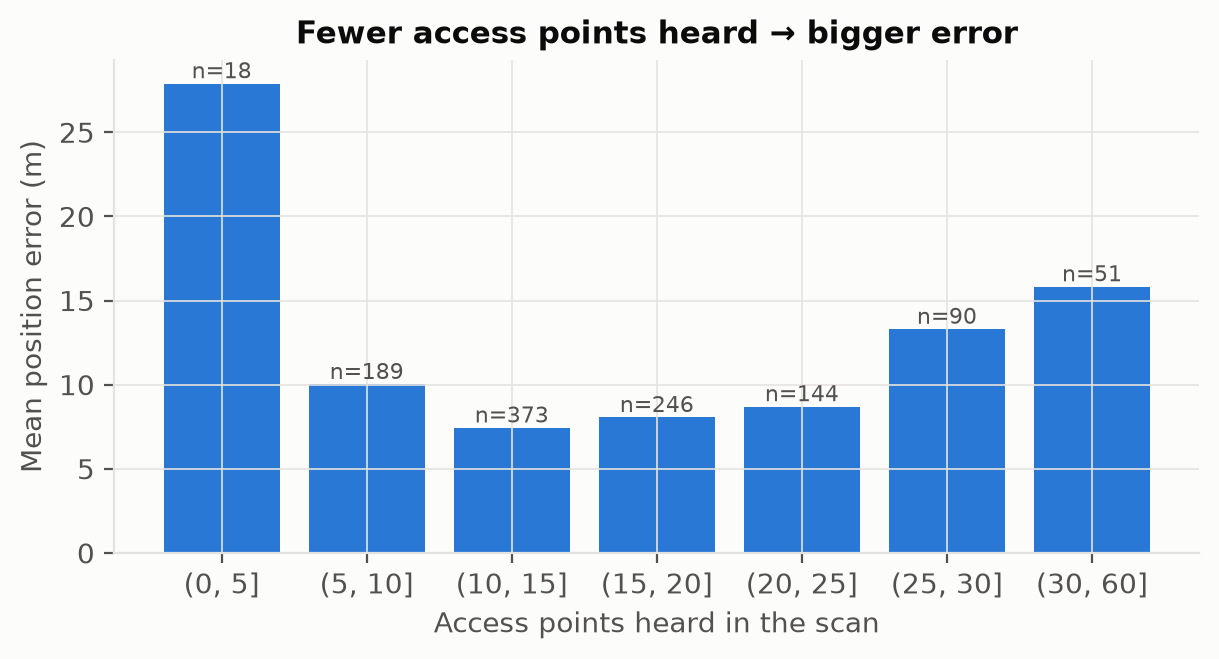

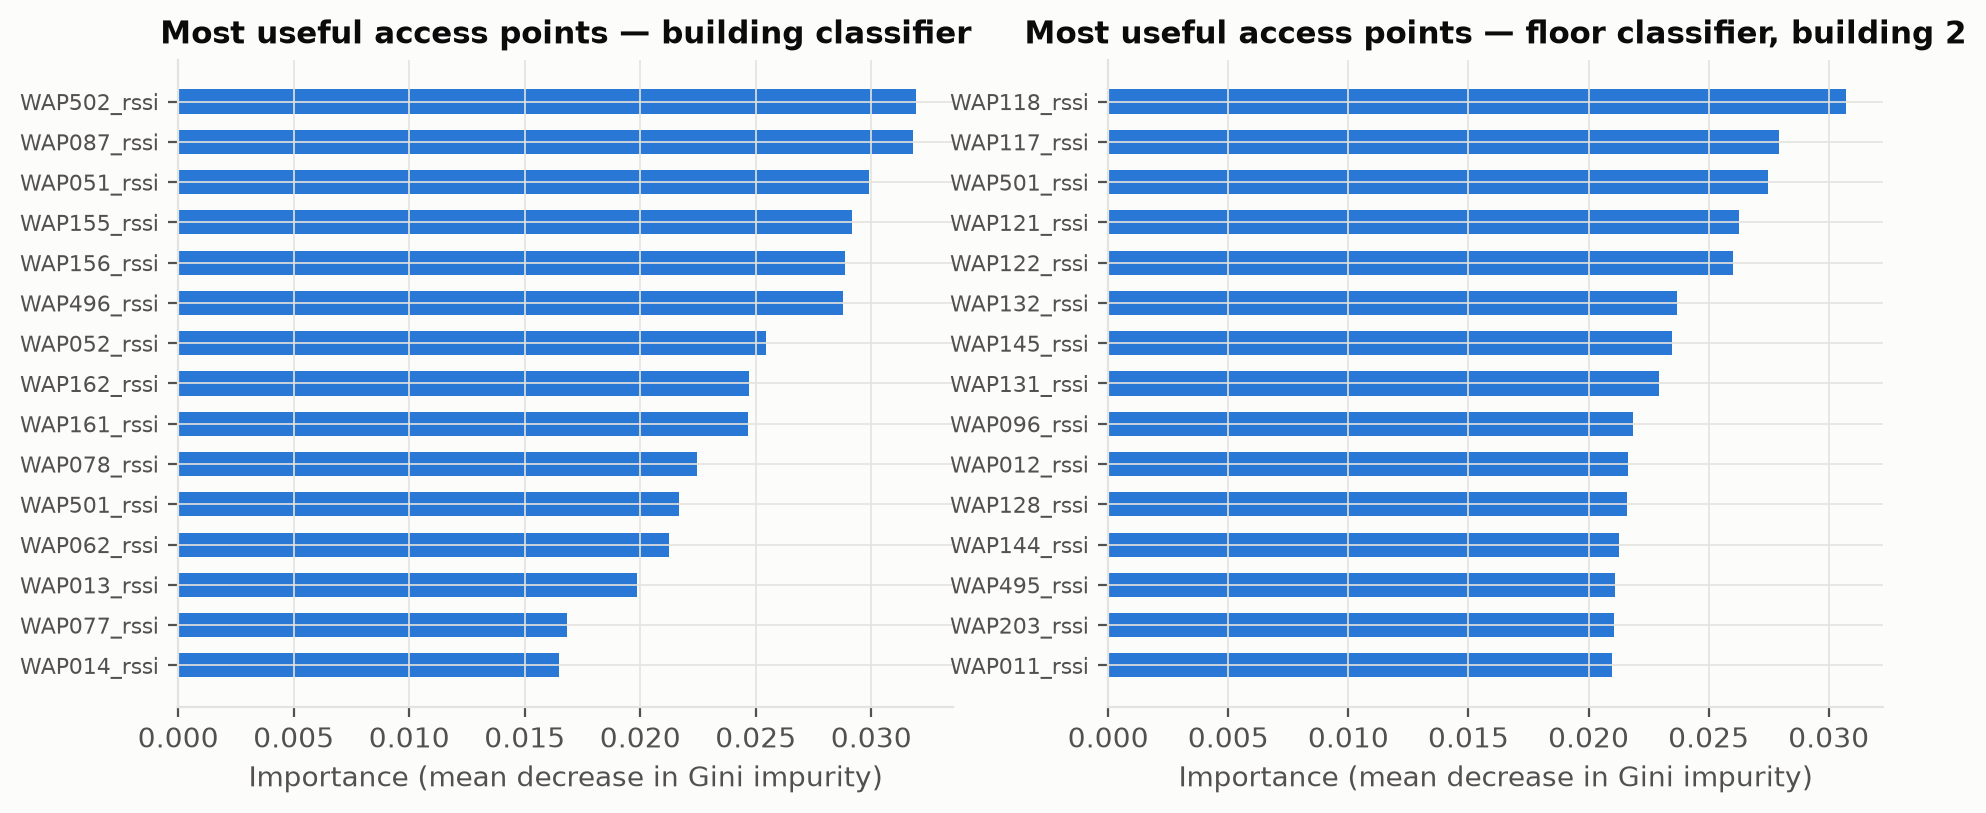

In [24]:
display(Image("../results/figures/per_phone_error.png"))
display(Image("../results/figures/error_vs_aps_heard.png"))
display(Image("../results/figures/feature_importance.png"))

In [25]:
pd.read_csv("../results/ablation_outliers.csv")[["training_set", "n_train", "building_floor_acc", "mean_error_m", "ipin_score_m"]]

,training_set,n_train,building_floor_acc,mean_error_m,ipin_score_m
0,all training scans,19227,0.912,9.366,9.805
1,without scans having RSSI > -30 dBm,18735,0.911,9.455,9.898


## 7. Gap identified for Phase 2

Our models treat building, floor and position as **separate problems**. The per-building forest links them only
through a hand-made "building first" step, and a wrong building sends the scan to the wrong sub-model. None of them
learns a representation of the ~465 interacting APs that all three tasks could share. Phase 2 trains a
**multitask MLP**: a shared trunk with two classification heads and one regression head, compared with
these baselines on exactly the same split and metrics.